# 09 — Clean image model: B0 screening and five-fold evaluation

Can an image model rank melanoma images above benign images? EfficientNet-B0
(B0) is a convolutional neural network: it learns image patterns such as edges,
texture and colour. Its starting weights were learned on ImageNet, a large
general-image dataset, before being adapted to this task.

Four training **recipes** (learning rate and class weighting) were compared.
An **epoch** is one pass through the fitting data; a **checkpoint** stores the
model's learned weights at an epoch. The saved first-inner-fold histories show each recipe's six-epoch screen.
Average precision (AP) chooses the screening recipe; three twelve-epoch
confirmations then determine the fixed duration of a fresh outer-training refit.

This is an **inner-validation pilot**: patients held out from fitting guide early
choices. Because those same labels helped choose recipes and epochs, these are
exploratory results. The second part of this notebook reads full out-of-fold (OOF) evaluation: the
complete selection process repeats inside each outer-training pool, then scores
its held-out patients. Outer fold 0 is excluded from the first pool's selection
examples, but later supplies its independent outer prediction. The reserved test
comes last and stays excluded from every section.

This notebook reads saved results without training or fitting calibration.
Original outputs are preserved; raw clean results use `b0_nested_dedup_v1`,
and report figures belong only to the numbered clean-workflow directory.
Continue with [architecture comparison](10_bounded_image_pilots.ipynb).


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [09_image_b0_pilot.ipynb](../Subset/09_image_b0_pilot.ipynb).

**Scope change:** original six-epoch pilot explanations remain beside the
clean screening evidence; full five-fold evaluation follows in the original
nested-report section order. These two evidence scopes are labelled separately.

## Setup and verification

Use the project's `.venv` environment. The checks below verify saved source,
settings, files and patient memberships, then independently recompute the
reported metrics. File hashes act as fingerprints: a changed file fails the
check. This protects the identity of the retained development predictions after code changes.
The clean manifest records 6,706 images rather than the original 6,864; all
422 patients and their five original outer groups remain present.
No reserved-test files are loaded.


In [1]:
NOTEBOOK_STAGE = '09_image_modelling'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary

from melanoma_detection import dedup_notebook_images as image_docs
from melanoma_detection.image_nested_calibration_reporting import load_saved_calibration_run
image_docs.original_style('image')
raw = load_image_report(ROOT)
calibration = load_saved_calibration_run(ROOT, image_docs.CALIBRATION_RUN)
display(pd.DataFrame([{'stage': 'raw five-fold B0', 'status': raw['status'], 'complete': raw['complete']},
    {'stage': 'training-only calibration', 'status': calibration['status'], 'complete': calibration['complete']}]))

# Preserve the original notebook's plotting defaults.
plt.rcParams.update({'font.size': 10, 'figure.facecolor': 'white', 'axes.facecolor': 'white'})
ORIGINAL_EXPORT_DPI = 130


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

,stage,status,complete
0,raw five-fold B0,complete,True
1,training-only calibration,complete,True


## Patients and image preparation

Keep all images from one patient in the same partition, so a model cannot learn
from a patient it later evaluates. The table distinguishes **fitting** patients,
**inner-validation** patients, and **outer-excluded** patients whose labels are
not used for that outer pool's recipe and duration selection.

Only RGB images enter the model. Each whole image is resized to 224 × 224 pixels
using bilinear interpolation. ImageNet normalisation rescales colour channels
to the range expected by the pretrained network. During fitting, weak random
flips and rotations add **augmentation**: varied views intended to discourage
memorising an image's orientation. Validation uses the same preparation every
time, without random augmentation.


In [2]:
image_docs.image_partition_table(ROOT, data, dataset_identity)
image_docs.image_settings(ROOT)

,partition,images,patients,malignant_images
0,fitting,3528,225,70
1,inner_validation,1834,113,33
2,outer_excluded,1344,84,24


,Setting,Value
0,architecture,efficientnet_b0
1,weights,IMAGENET1K_V1
2,image_size,224
3,dropout,0.2
4,augmentation,weak
5,preprocessing,none
6,microbatch,64
7,effective_batch,64
8,min_microbatch,4
9,head_lr,0.001


,id,backbone_lr,loss_weight
0,lr3e5_none,0.00003,none
1,lr1e4_none,0.00010,none
2,lr3e5_sqrt,0.00003,sqrt_ratio
3,lr1e4_sqrt,0.00010,sqrt_ratio


,Outer folds,Preserved inner folds,Screen epochs,Confirm epochs,Duration,Raw GPU fits,Calibration GPU fits,Fresh start
0,5,3,6,12,median of three saved AP-best epochs,35,15,IMAGENET1K_V1 for each distinct fit


**Read the preview:** each row is one fitting image; the left column is the
original and the next three columns are seeded weak variants. `target=1` means
melanoma and `target=0` benign. Compare lesion edges, texture and colour across
the row. Rotation can create black corners or remove peripheral pixels; an
intact centre alone does not prove that the whole lesion is preserved. This
deliberate label mix is a quality check, not a representative prevalence sample.


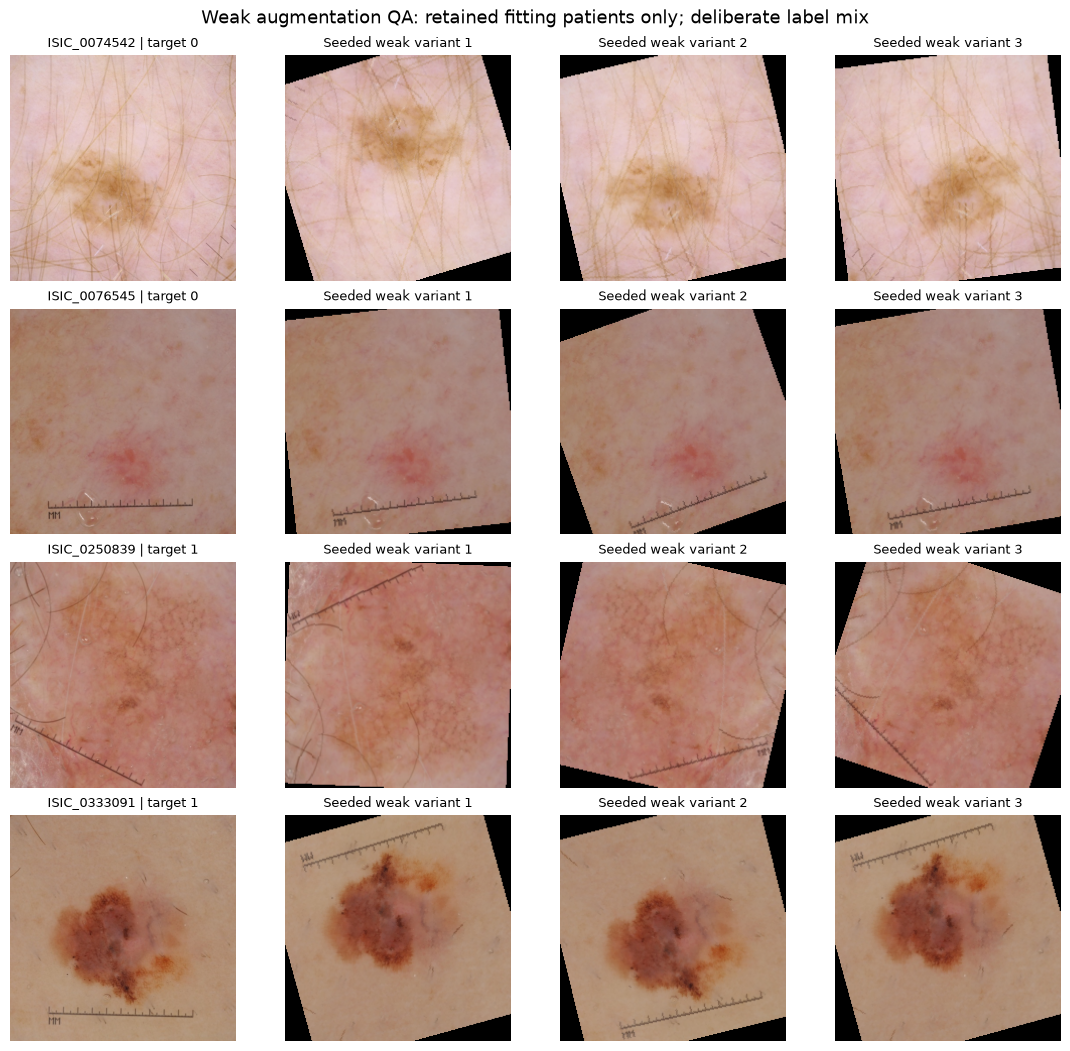

Colour is displayed after reversing ImageNet normalisation. Weak rotation can leave black corners or clip framing; these previews document the preserved transform and do not approve a new augmentation profile.

In [3]:
image_docs.show_preparation(ROOT, data, dataset_identity, finish_figure)

## Prediction quality and computing cost

**AP** summarises precision (how many flagged images are malignant) as recall
(how many malignant images are found) changes across score cutoffs. Higher is
better; the malignant-image fraction is a useful chance-ranking reference.
**ROC-AUC** measures ranking across both classes; higher is better and 0.5 is
chance ranking. AP deserves attention because malignant images are rare.
**Log loss** penalises confident wrong scores; **Brier score** averages squared
score errors. Lower is better for both, but a low loss alone can hide poor
melanoma detection in an imbalanced dataset.

These outputs are prediction **scores**, not verified clinical probabilities.
Class weighting gives malignant fitting examples more influence and can change
the score scale. The constant fitting-prevalence row is a simple baseline.

In every outer-training pool all four recipes were screened for six epochs, including one classifier-only warmup before
adapting the whole network. The fixed learning-rate schedule spans 30 epochs;
that schedule is distinct from the executed six-epoch budget and selected epoch.
Exact AP ties retain the earlier checkpoint within a fit. Screening recipes
within 0.0001 of maximum AP tie, preferring no weighting then lower learning rate.
The median AP-best epoch across three confirmations fixes each fresh outer refit. The resource table reports measured
epoch time and allocated GPU memory, excluding setup/download overhead.


In [4]:
image_docs.image_selection_table(ROOT, data)
if raw['complete']:
    display(raw['fold_metrics'])

,outer_fold,outer_images,outer_malignant_images,selected_recipe,inner_best_epochs,fixed_refit_epochs,status
0,0,1344,24,lr1e4_none,"[7, 11, 11]",11,complete
1,1,1366,26,lr1e4_none,"[9, 12, 7]",9,complete
2,2,1328,26,lr1e4_none,"[4, 3, 12]",4,complete
3,3,1371,25,lr1e4_none,"[8, 9, 10]",9,complete
4,4,1297,26,lr1e4_none,"[4, 9, 8]",8,complete


,fold,n_images,n_patients,n_positive,prevalence,average_precision,roc_auc,log_loss,brier
0,0,1344,84,24,0.017857,0.152537,0.854419,0.095513,0.022482
1,1,1366,84,26,0.019034,0.148876,0.839179,0.090245,0.019154
2,2,1328,87,26,0.019578,0.148730,0.864823,0.082345,0.018674
3,3,1371,82,25,0.018235,0.057262,0.757266,0.138206,0.018364
4,4,1297,85,26,0.020046,0.150444,0.838316,0.089270,0.019511


## Learning over epochs

**Read the first figure:** the horizontal axis is completed epoch; each line is
one recipe. The upper panels show AP and ROC-AUC (higher is better); the lower
panels show validation log loss and Brier (lower is better). Horizontal guides
mark prevalence for AP and 0.5 for ROC-AUC. Hollow rings mark the epoch chosen
by AP in every panel, rather than each panel's separate optimum. The dotted
vertical line separates classifier warmup from whole-network fine-tuning.

**Read the second figure:** epoch is horizontal and fitting binary cross-entropy
(BCE), the training objective, is vertical. Falling loss shows a closer fit to
training labels; improvement should also appear on validation. Panels separate
weighted and unweighted objectives because their magnitudes are not comparable.
A late AP peak motivates further checking, not proof that longer training helps.
The plotted four-recipe screen is restricted to epochs 1–6 even when its selected
trajectory subsequently continued to twelve. This keeps the original learning-curve
comparison on a common budget; the separate selection table documents all confirmations.


,outer_fold,outer_images,outer_malignant_images,selected_recipe,inner_best_epochs,fresh_outer_refit_epochs,outer_status
0,0,1344,24,lr1e4_none,"[7, 11, 11]",11,complete
1,1,1366,26,lr1e4_none,"[9, 12, 7]",9,complete
2,2,1328,26,lr1e4_none,"[4, 3, 12]",4,complete
3,3,1371,25,lr1e4_none,"[8, 9, 10]",9,complete
4,4,1297,26,lr1e4_none,"[4, 9, 8]",8,complete


,outer_fold,recipe,screen_epochs_available,best_screen_epoch,screen_AP,screen_AUC,scope
0,0,lr1e4_none,6,4,0.148514,0.860751,inner selection diagnostic
1,0,lr1e4_sqrt,6,4,0.118139,0.860549,inner selection diagnostic
2,0,lr3e5_none,6,4,0.138282,0.835209,inner selection diagnostic
3,0,lr3e5_sqrt,6,4,0.131890,0.855972,inner selection diagnostic
4,1,lr1e4_none,6,5,0.158030,0.821047,inner selection diagnostic
5,1,lr1e4_sqrt,6,6,0.150037,0.806697,inner selection diagnostic
6,1,lr3e5_none,6,6,0.149604,0.842220,inner selection diagnostic
7,1,lr3e5_sqrt,6,6,0.134236,0.836821,inner selection diagnostic
8,2,lr1e4_none,6,4,0.210262,0.812835,inner selection diagnostic
9,2,lr1e4_sqrt,6,5,0.129671,0.825605,inner selection diagnostic


,outer_fold,recipe,inner_fold,epochs,status,training_minutes,peak_GPU_GiB
0,0,lr1e4_none,0,12,complete,7.613925,2.812526
1,0,lr1e4_none,1,12,complete,8.133338,2.812526
2,0,lr1e4_none,2,12,complete,6.767769,2.812526
3,0,lr1e4_sqrt,0,6,complete,3.819540,2.812526
4,0,lr3e5_none,0,6,complete,4.188335,2.813129
5,0,lr3e5_sqrt,0,6,complete,3.877970,2.812526
6,1,lr1e4_none,0,12,complete,7.072982,2.812526
7,1,lr1e4_none,1,12,complete,7.600634,2.812526
8,1,lr1e4_none,2,12,complete,7.404213,2.812526
9,1,lr1e4_sqrt,0,6,complete,3.139322,2.812526


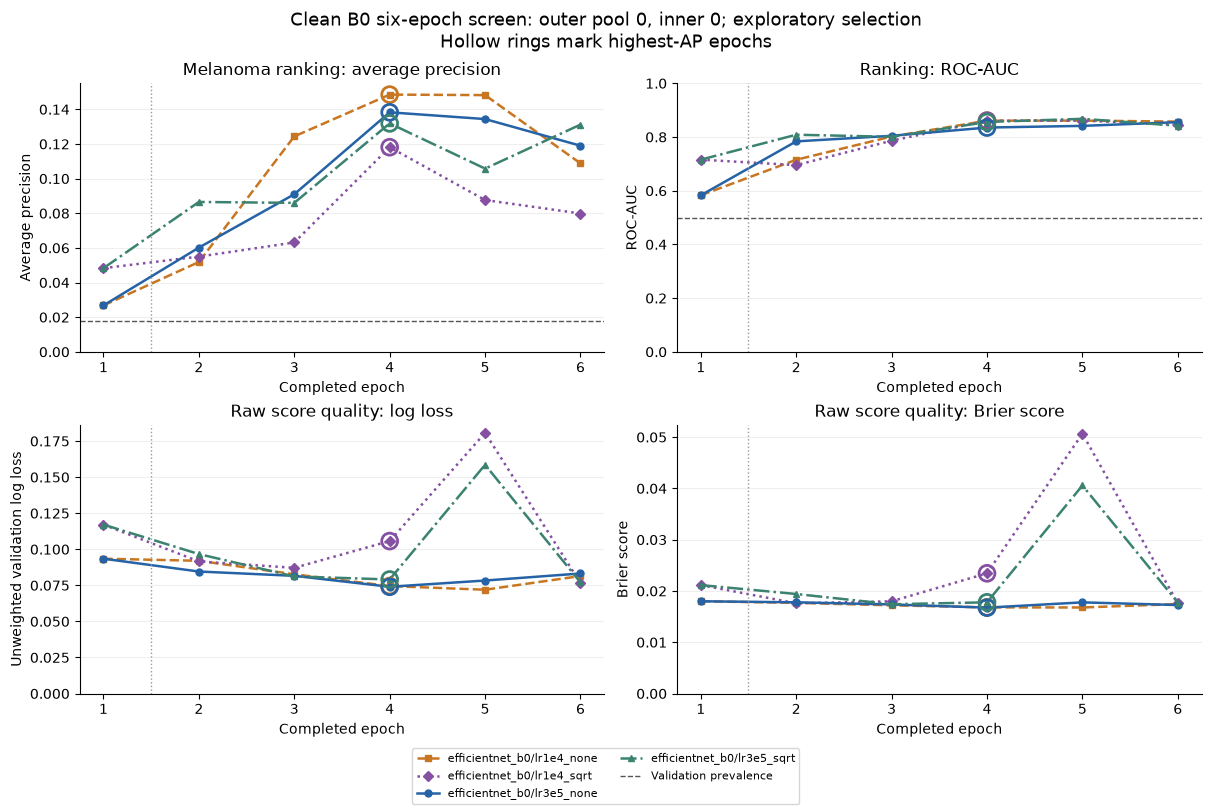

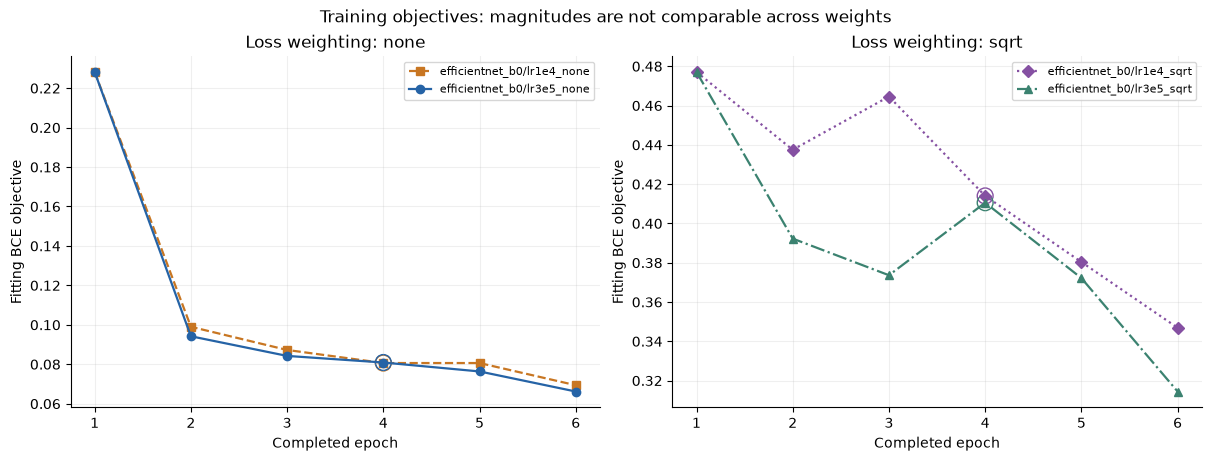

In [5]:
image_docs.image_progress(ROOT, data, dataset_identity, finish_figure)

## ROC and precision–recall curves

**Read the curves:** the original two-panel ROC/precision–recall composition now shows the
verified retained outer predictions on matching records. Moving along a line changes the score cutoff.
The left panel plots false-positive rate (benign images flagged) horizontally
against recall/sensitivity (malignant images found) vertically; curves closer
to the upper left rank better than the chance diagonal. The right panel plots
recall horizontally against precision vertically. Higher precision at the same
recall is better; the horizontal guide shows malignant-image prevalence.

AP summarises precision–recall ranking; it is not the trapezoidal area under
the plotted steps. Neither curve selects a practical cutoff. **Scope change:** inner-screen best-checkpoint predictions were not exported
by the clean bounded runner, so these are outer OOF curves rather than the original
one-split pilot curves. No missing inner predictions are reconstructed by inference.
Pooled curves are secondary; unweighted mean-fold metrics remain the primary summary.


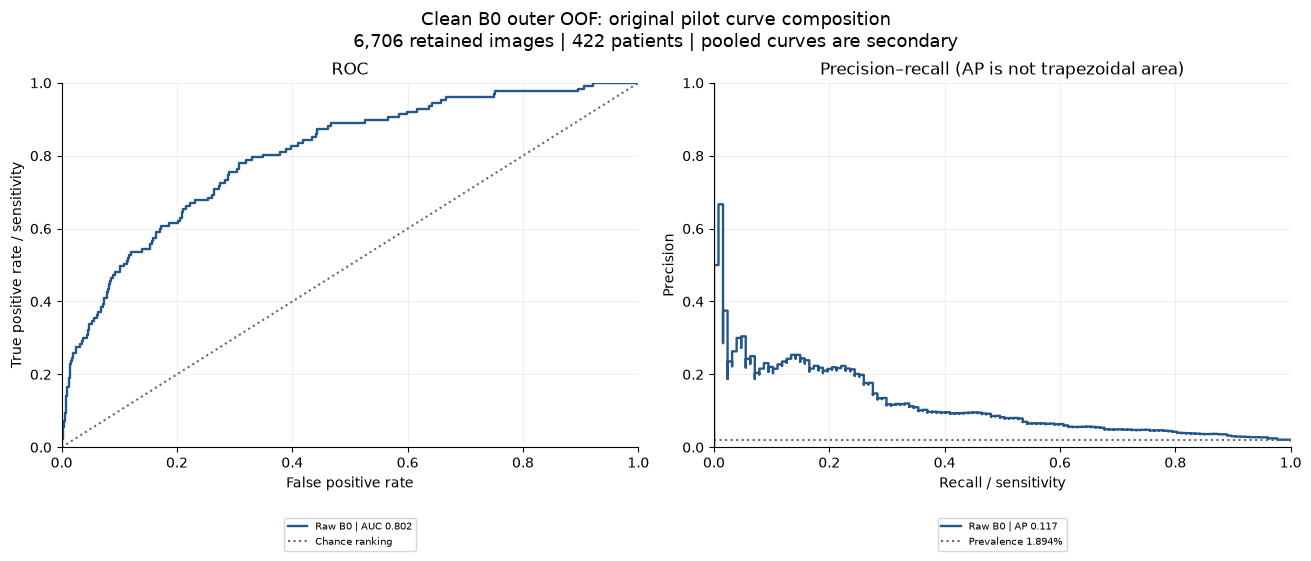

In [6]:
if raw['complete']:
    image_docs.plot_probability_views(raw['predictions'], {'Raw B0': 'base_probability'}, finish_figure, 'raw_b0', 'Clean B0 outer OOF: original pilot curve composition', reliability=False)

## Classification at the fixed score cutoff 0.5

An image is flagged when `base_probability >= 0.5`; this stored column contains
an uncalibrated score despite its name. The cutoff is declared, not tuned here. This report uses verified retained outer predictions, while the original
pilot used selected inner-validation checkpoints.
Recall/sensitivity measures malignant images found; specificity measures benign
images correctly left unflagged. Precision measures malignancy among flags;
F1 balances precision and recall. Undefined ratios remain missing.

**Read each confusion matrix:** rows are true class and columns predicted class.
The diagonal contains correct decisions. Bottom left contains missed melanoma
images (false negatives); top right contains benign images flagged (false
positives). Cell text gives counts and percentages within each true-class row;
darker blue means a larger row fraction. Compare both errors rather than the
many correct benign images. A strong ranking score does not guarantee useful
recall at this cutoff. The later 80%-recall scenario requires training-only OOF
scores; outer evaluation labels must not choose a threshold.


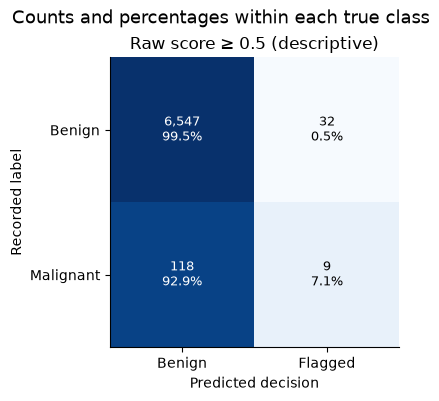

,scenario,TN,FP,FN,TP,recall,precision,specificity,flagged_images
0,Raw score ≥ 0.5 (descriptive),6547,32,118,9,0.070866,0.219512,0.995136,41


In [7]:
if raw['complete']:
    image_docs.plot_confusions(raw['predictions'], {'Raw score ≥ 0.5 (descriptive)': raw['predictions'].base_probability.ge(.5)}, finish_figure, 'raw_b0')

## Descriptive reliability of the scores

**Read the reliability panels:** the panel describes the verified raw outer predictions. Similar scores are
grouped into the original nested report's ten fixed-width bins; horizontal position is the bin's mean score and
vertical position is its observed melanoma fraction. The diagonal means score
and frequency agree. Points below it indicate scores exceeding the observed
frequency; points above it indicate the reverse. The reliability panel retains the full [0,1] range, with bin image counts
annotated; the adjacent histogram shows the score distribution on the same range.
**Scope change:** this follows the original five-fold report's fixed bins instead
of substituting its pilot's five equal-count recipe panels.

The table gives each bin's image, patient and malignant-image counts. Few
malignant images and repeated images from a patient make the estimates noisy.
This describes reliability; it does not fit a calibrator (a score-to-probability
mapping) or establish accurate clinical probabilities.


,bin,lower,upper,n_images,n_positive,mean_probability,observed_prevalence
0,0,0.0,0.1,6499,92,0.005610,0.014156
1,1,0.1,0.2,98,12,0.137267,0.122449
2,2,0.2,0.3,33,4,0.241452,0.121212
3,3,0.3,0.4,18,7,0.339054,0.388889
4,4,0.4,0.5,17,3,0.442833,0.176471
5,5,0.5,0.6,14,2,0.544697,0.142857
6,6,0.6,0.7,7,1,0.639248,0.142857
7,7,0.7,0.8,4,3,0.775557,0.750000
8,8,0.8,0.9,3,0,0.884586,0.000000
9,9,0.9,1.0,13,3,0.954277,0.230769


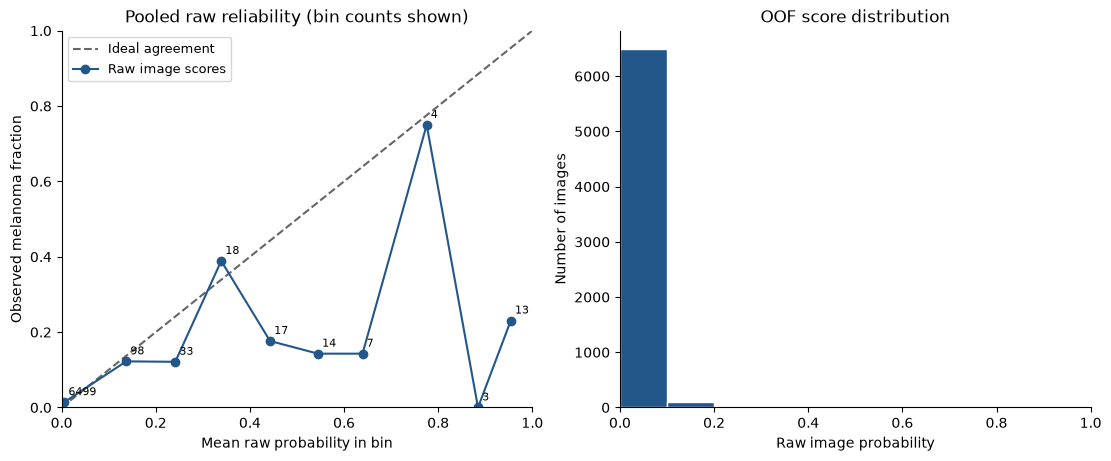

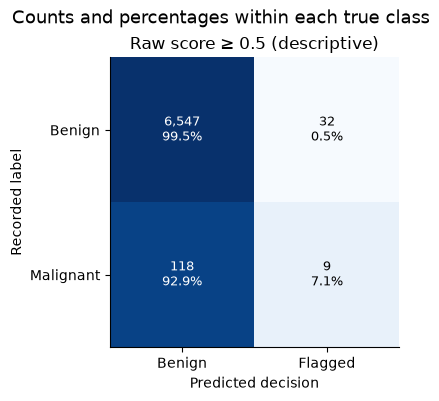

,scenario,TN,FP,FN,TP,recall,precision,specificity,flagged_images
0,Raw score ≥ 0.5 (descriptive),6547,32,118,9,0.070866,0.219512,0.995136,41


In [8]:
image_docs.raw_outer_reliability(raw, finish_figure)

## Interpretation and next steps

The saved clean screen and confirmation table reports each selected recipe and
its three AP-best epochs. Read the executed recap below instead of carrying
forward the original pilot's AP 0.1383 or preferred epoch: those belonged to
different, duplicate-containing fitting and validation records. A late screen
peak can motivate checking duration on further patient splits, but does not
establish an optimal duration or make B0 the final architecture.

[Notebook 10](10_bounded_image_pilots.ipynb) documents the narrower clean duration
and ConvNeXt-Tiny pilots, with DenseNet, stronger augmentation and lighting
correction explicitly deferred. [Notebook 11](11_image_uncertainty.ipynb) reads
clean five-fold uncertainty diagnostics. The following nested-evaluation sections
verify B0's five outer refits and the separate training-only calibration records.
Any fusion and the independent reserved test remain later work after the entire
procedure, calibration choice and decision rule are settled.

In [9]:
image_docs.image_takeaways(raw, comparison_table())

**Executed clean B0 result:** mean outer-fold AP **0.1316** and mean ROC-AUC **0.8308**. AP ranges from **0.057 to 0.153** across the five retained patient groups. The observed fold spread is descriptive variability, not a confidence interval. These values replace the historical pilot findings; they remain development evidence after earlier exploration.

,population,model,aggregation,fold,weighting,n_images,n_patients,n_malignant_images,n_malignant_patients,average_precision,roc_auc,log_loss,brier,role
7,clean,b0_raw,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.131570,0.830801,0.099116,0.019637,predeclared
10,clean,metadata_nn_mean,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.059570,0.676694,0.090169,0.018382,predeclared
17,clean,spline_raw,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.064842,0.655631,0.091006,0.018422,predeclared


## Limitations

- One inner patient split and six epochs show early behaviour, not final performance.
- Recipe and epoch choices reuse these validation labels, which can make results optimistic.
- Class-weighted scores are uncalibrated; 0.5 is a reporting cutoff with potentially low recall.
- Weighted/unweighted fitting losses have different scales and cannot rank recipes against each other.
- A finite image preview cannot certify every lesion; the verified full outer report follows below and the reserved test remains pending.
- Exact-copy removal changes both fitting weight and evaluation weight; it does not undo earlier development exploration.


## Summary

The saved retained six-epoch screens provide verified B0 selection diagnostics;
the five-fold report below evaluates the resulting bounded procedure. Read AP alongside
the fixed-cutoff errors, score reliability and computing cost. The observations
below guide further experiments; they do not select the final architecture.


In [10]:
image_docs.image_selection_table(ROOT, data)

,outer_fold,outer_images,outer_malignant_images,selected_recipe,inner_best_epochs,fixed_refit_epochs,status
0,0,1344,24,lr1e4_none,"[7, 11, 11]",11,complete
1,1,1366,26,lr1e4_none,"[9, 12, 7]",9,complete
2,2,1328,26,lr1e4_none,"[4, 3, 12]",4,complete
3,3,1371,25,lr1e4_none,"[8, 9, 10]",9,complete
4,4,1297,26,lr1e4_none,"[4, 9, 8]",8,complete


# Clean image model: five preserved outer folds

## tl;dr

This report evaluates the bounded B0 recipe and duration selection process on five patient
groups. Each outer fold supplies predictions from a model that did not use its
patients for fitting, recipe selection or epoch selection in this run.
The primary measure is **mean outer-fold average precision (AP)**. AP measures
how effectively melanoma images appear near the top of the model's ranking.
Higher is better; fold prevalence supplies a simple ranking baseline.

The notebook reads saved results only. It does not start training, fit
calibration, choose a cutoff or open the reserved test. A partial run displays
its progress and withholds final five-fold conclusions.


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [14_image_nested_evaluation.ipynb](../Subset/14_image_nested_evaluation.ipynb).

**Scope change:** exact copies are removed before fitting and evaluation.
The five-fold design matches the original nested-evaluation report; original pilot
outputs are never substituted for missing clean results.

In [11]:
image_docs.original_style('image')
ORIGINAL_EXPORT_DPI = 150


## Context & Methods

The outer folds are the five existing patient groups in the frozen dedup_v1
development manifest; all 422 original patient assignments are preserved. The complete process repeats independently inside every outer
training pool:

1. Preserve the three recorded inner patient folds after removing exact copies. On the first inner fold, screen all **four
   B0 recipes for six epochs**: learning rate 3e-5 or 1e-4, crossed with unweighted
   or square-root-weighted loss. Only fitting patients determine the loss weight.
2. Choose the recipe with the highest screening AP. Scores within 0.0001 of the
   maximum tie; prefer unweighted loss and then the lower learning rate.
3. Confirm that selected recipe for **twelve total epochs on all three inner
   folds**. The compatible six-epoch first-fold checkpoint continues to twelve;
   the other two confirmation fits begin afresh.
4. Select the highest-AP epoch separately in each confirmation fit; exact ties
   keep the earlier epoch. The **median of those three best epochs** fixes the
   duration of a fresh refit on all outer training patients.
5. Predict the outer fold only after the fixed-duration refit completes. Outer
   labels do not guide fitting, recipe selection, epoch choice or stopping.

Confirmation AP chooses epochs inside training data; it is not outer performance.
The recipe and refit duration can differ between outer folds. Each retained
image must receive exactly one outer prediction; missing, duplicate, extra or
relabelled rows fail verification.

### Key Assumptions

Images from one patient remain together in every partition. AP and other
metrics concern individual images; the uncertainty calculation resamples
**patients**, keeping all their images together. Patients are sampled with
replacement separately within each fixed outer fold. Draws lacking either
outcome in any fold are discarded consistently across all reported measures.
The report records requested, retained and rejected draws.

These intervals condition on the saved models, recipe choices and folds. They
do not represent variability from retraining or repeating model selection.
Mean fold AP is primary because scores from separate fitted models can have
different scales; pooled AP is a secondary description.

Earlier architecture, augmentation and recipe pilots used the original development
population, and archived exploratory predictions used outer fold 0. Exact-copy removal
does not undo those earlier choices or make these patients newly untouched. This is
stronger **development evaluation**, but prior adaptation limits how fully it
represents an untouched evaluation. Freeze remaining decisions before the
single reserved-test evaluation.


In [12]:
image_docs.image_settings(ROOT)

,Setting,Value
0,architecture,efficientnet_b0
1,weights,IMAGENET1K_V1
2,image_size,224
3,dropout,0.2
4,augmentation,weak
5,preprocessing,none
6,microbatch,64
7,effective_batch,64
8,min_microbatch,4
9,head_lr,0.001


,id,backbone_lr,loss_weight
0,lr3e5_none,0.00003,none
1,lr1e4_none,0.00010,none
2,lr3e5_sqrt,0.00003,sqrt_ratio
3,lr1e4_sqrt,0.00010,sqrt_ratio


,Outer folds,Preserved inner folds,Screen epochs,Confirm epochs,Duration,Raw GPU fits,Calibration GPU fits,Fresh start
0,5,3,6,12,median of three saved AP-best epochs,35,15,IMAGENET1K_V1 for each distinct fit


### Recorded recipe and refit duration by outer fold

Each completed outer fold records the recipe chosen on its first inner split
and the fixed refit duration obtained from three confirmation fits. This table
documents what was selected, rather than ranking recipes using outer labels.
An unfinished fold keeps missing settings until its selection is saved.


In [13]:
image_docs.image_selection_table(ROOT, data)

,outer_fold,outer_images,outer_malignant_images,selected_recipe,inner_best_epochs,fixed_refit_epochs,status
0,0,1344,24,lr1e4_none,"[7, 11, 11]",11,complete
1,1,1366,26,lr1e4_none,"[9, 12, 7]",9,complete
2,2,1328,26,lr1e4_none,"[4, 3, 12]",4,complete
3,3,1371,25,lr1e4_none,"[8, 9, 10]",9,complete
4,4,1297,26,lr1e4_none,"[4, 9, 8]",8,complete


## Data

The verified population is the complete retained development cohort: 6,706 images, 422 patients,
127 malignant images and 88 patients with a malignant image. Counts
by fold make rare melanoma support and unequal image counts visible. All
models are scored on the same images when a metadata comparison is available.
No inner join can silently reduce the evaluation population.


In [14]:
if raw['complete']:
    display(raw['fold_metrics'][['fold', 'n_images', 'n_patients', 'n_positive', 'prevalence']])
else:
    display(Markdown('**Pending:** full retained population counts require five verified folds.'))

,fold,n_images,n_patients,n_positive,prevalence
0,0,1344,84,24,0.017857
1,1,1366,84,26,0.019034
2,2,1328,87,26,0.019578
3,3,1371,82,25,0.018235
4,4,1297,85,26,0.020046


## Results

### Ranking and fold variation

The fold table and AP plot show how ranking performance varies between patient
groups. The spread between five fold scores is descriptive variability, not a
confidence interval. Precision–recall is particularly informative here because
melanoma images are uncommon; ROC shows a complementary ranking view.


,fold,n_images,n_patients,n_positive,prevalence,average_precision,roc_auc,log_loss,brier
0,0,1344,84,24,0.0179,0.1525,0.8544,0.0955,0.0225
1,1,1366,84,26,0.0190,0.1489,0.8392,0.0902,0.0192
2,2,1328,87,26,0.0196,0.1487,0.8648,0.0823,0.0187
3,3,1371,82,25,0.0182,0.0573,0.7573,0.1382,0.0184
4,4,1297,85,26,0.0200,0.1504,0.8383,0.0893,0.0195


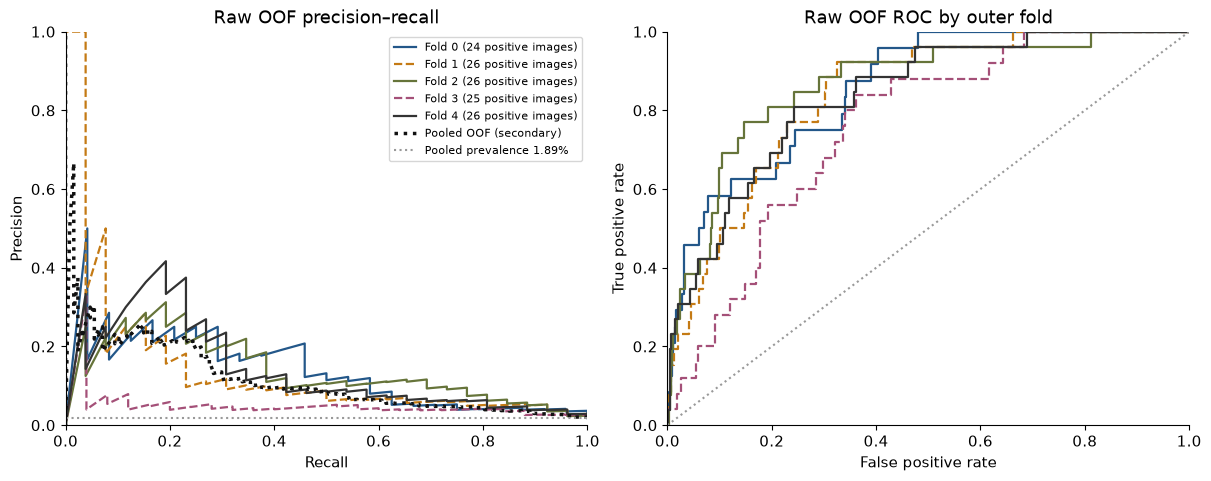

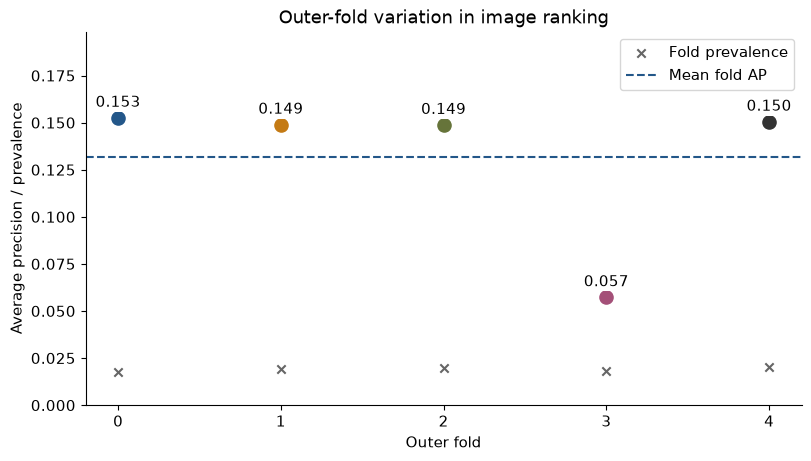

In [15]:
image_docs.raw_outer_ranking(raw, finish_figure)

### Raw probabilities and the declared 0.5 cutoff

Log loss and Brier score examine probability quality; lower is better. The
reliability plot compares mean raw score with the observed melanoma fraction
in fixed bins, and shows how many images support each point. It is descriptive:
sparse bins can be unstable. Class weighting can alter raw probability scale.

The confusion counts use the declared rule **raw score ≥ 0.5**. This cutoff is
a transparent default illustration, not a tuned operating point or a clinical
recommendation. No new threshold or calibration model is fitted by this report. The ten fixed-width
bins, image-count annotations and score histogram retain the original composition.
The added confusion panel reports both counts and percentages within true-class rows,
using the same blue scale as the original pilot notebooks.


,bin,lower,upper,n_images,n_positive,mean_probability,observed_prevalence
0,0,0.0,0.1,6499,92,0.005610,0.014156
1,1,0.1,0.2,98,12,0.137267,0.122449
2,2,0.2,0.3,33,4,0.241452,0.121212
3,3,0.3,0.4,18,7,0.339054,0.388889
4,4,0.4,0.5,17,3,0.442833,0.176471
5,5,0.5,0.6,14,2,0.544697,0.142857
6,6,0.6,0.7,7,1,0.639248,0.142857
7,7,0.7,0.8,4,3,0.775557,0.750000
8,8,0.8,0.9,3,0,0.884586,0.000000
9,9,0.9,1.0,13,3,0.954277,0.230769


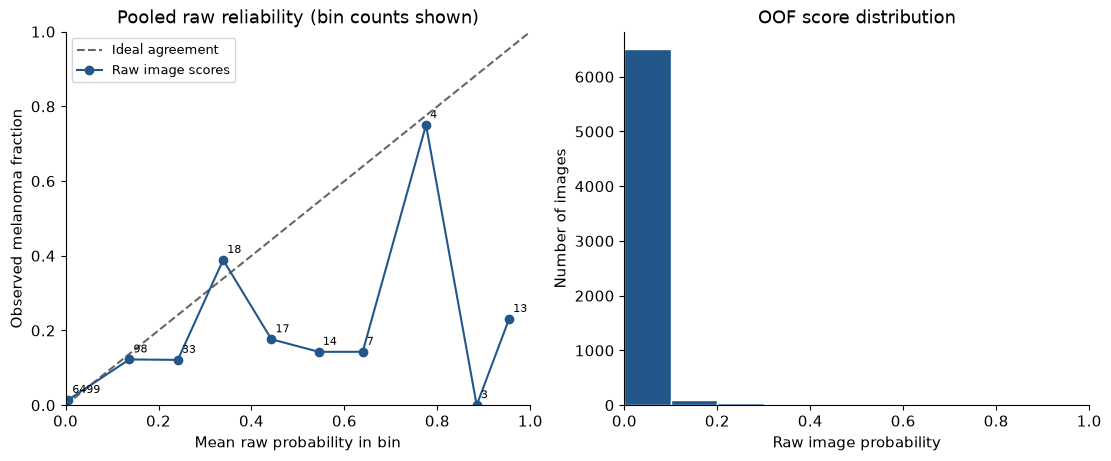

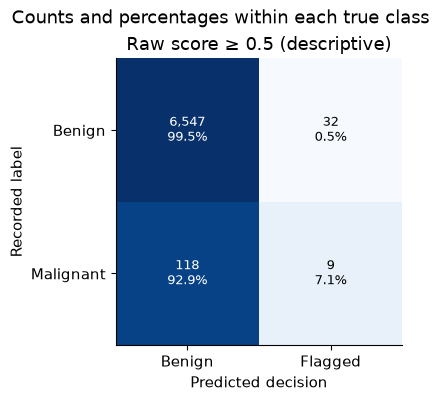

,scenario,TN,FP,FN,TP,recall,precision,specificity,flagged_images
0,Raw score ≥ 0.5 (descriptive),6547,32,118,9,0.070866,0.219512,0.995136,41


In [16]:
image_docs.raw_outer_reliability(raw, finish_figure)

### Optional training-only calibration and the 80%-recall scenario

This separate stage has its own run directory. Its clean artifacts are read only after the raw
five-fold evaluation verifies. Three fresh fixed-duration inner refits per
outer fold were the separate training-only calibration protocol; opening this
notebook starts none of those fits. Each uses that outer pool's already
selected recipe and median epoch duration. Its training-only OOF predictions
fit a logistic calibration map on logits (`C=1`) and choose the highest cutoff
reaching 80% malignant recall on those training predictions. A failed or
non-positive-slope map is recorded and leaves the separate calibration stage
incomplete; the raw report remains available. Complete frozen maps and cutoffs
are then applied to the unchanged raw outer predictions.

All five calibration folds must finish and their clean receipts must verify
before the comparisons below appear; the status table reports actual completion.
Calibration is assessed through held-out log loss, Brier and reliability.
Positive-slope maps preserve ordering within a fold, so fold AP/ROC-AUC should
stay the same; numerical clipping or ties require inspection if they change.
Pooled AP may change when the five folds' score scales change.

The 80% recall value is a **training selection target**, not a promise about
actual outer recall or a clinically validated target. Report the actual held-out
recall, precision, F1, specificity and confusion counts. Calibration maps and
cutoffs remain fixed in the reported conditional bootstrap intervals. The raw
five-fold status and matched metadata comparison remain unchanged.


,fold,n_images,n_patients,n_positive,prevalence,average_precision,roc_auc,log_loss,brier,model
0,0,1344,84,24,0.017857,0.152537,0.854419,0.095513,0.022482,raw
1,1,1366,84,26,0.019034,0.148876,0.839179,0.090245,0.019154,raw
2,2,1328,87,26,0.019578,0.148730,0.864823,0.082345,0.018674,raw
3,3,1371,82,25,0.018235,0.057262,0.757266,0.138206,0.018364,raw
4,4,1297,85,26,0.020046,0.150444,0.838316,0.089270,0.019511,raw
5,0,1344,84,24,0.017857,0.152537,0.854419,0.090409,0.017738,calibrated
6,1,1366,84,26,0.019034,0.148876,0.839179,0.078001,0.017527,calibrated
7,2,1328,87,26,0.019578,0.148730,0.864823,0.076806,0.018044,calibrated
8,3,1371,82,25,0.018235,0.057262,0.757266,0.089645,0.017793,calibrated
9,4,1297,85,26,0.020046,0.150444,0.838316,0.087645,0.018813,calibrated


,fold,raw_average_precision,calibrated_average_precision,ap_difference,raw_roc_auc,calibrated_roc_auc,ap_invariant,roc_auc_invariant,changed_training_selected_decisions
0,0,0.152537,0.152537,0.000000e+00,0.854419,0.854419,True,True,0
1,1,0.148876,0.148876,0.000000e+00,0.839179,0.839179,True,True,0
2,2,0.148730,0.148730,0.000000e+00,0.864823,0.864823,True,True,0
3,3,0.057262,0.057262,-6.938894e-18,0.757266,0.757266,True,True,0
4,4,0.150444,0.150444,0.000000e+00,0.838316,0.838316,True,True,0


,fold,model,n_images,n_patients,n_positive,training_target_recall,threshold,threshold_scope,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction,recall,f1
0,0,raw,1344,84,24,0.8,0.000056,fixed per outer fold from training-only OOF sc...,24,1207,113,0,1.000000,0.085606,0.019496,0.915923,1.000000,0.038247
1,0,calibrated,1344,84,24,0.8,0.016348,fixed per outer fold from training-only OOF sc...,24,1207,113,0,1.000000,0.085606,0.019496,0.915923,1.000000,0.038247
2,1,raw,1366,84,26,0.8,0.002104,fixed per outer fold from training-only OOF sc...,24,490,850,2,0.923077,0.634328,0.046693,0.376281,0.923077,0.088889
3,1,calibrated,1366,84,26,0.8,0.017208,fixed per outer fold from training-only OOF sc...,24,490,850,2,0.923077,0.634328,0.046693,0.376281,0.923077,0.088889
4,2,raw,1328,87,26,0.8,0.006221,fixed per outer fold from training-only OOF sc...,22,336,966,4,0.846154,0.741935,0.061453,0.269578,0.846154,0.114583
5,2,calibrated,1328,87,26,0.8,0.015723,fixed per outer fold from training-only OOF sc...,22,336,966,4,0.846154,0.741935,0.061453,0.269578,0.846154,0.114583
6,3,raw,1371,82,25,0.8,0.001956,fixed per outer fold from training-only OOF sc...,7,148,1198,18,0.280000,0.890045,0.045161,0.113056,0.280000,0.077778
7,3,calibrated,1371,82,25,0.8,0.018041,fixed per outer fold from training-only OOF sc...,7,148,1198,18,0.280000,0.890045,0.045161,0.113056,0.280000,0.077778
8,4,raw,1297,85,26,0.8,0.000228,fixed per outer fold from training-only OOF sc...,25,838,433,1,0.961538,0.340677,0.028969,0.665382,0.961538,0.056243
9,4,calibrated,1297,85,26,0.8,0.015263,fixed per outer fold from training-only OOF sc...,25,838,433,1,0.961538,0.340677,0.028969,0.665382,0.961538,0.056243


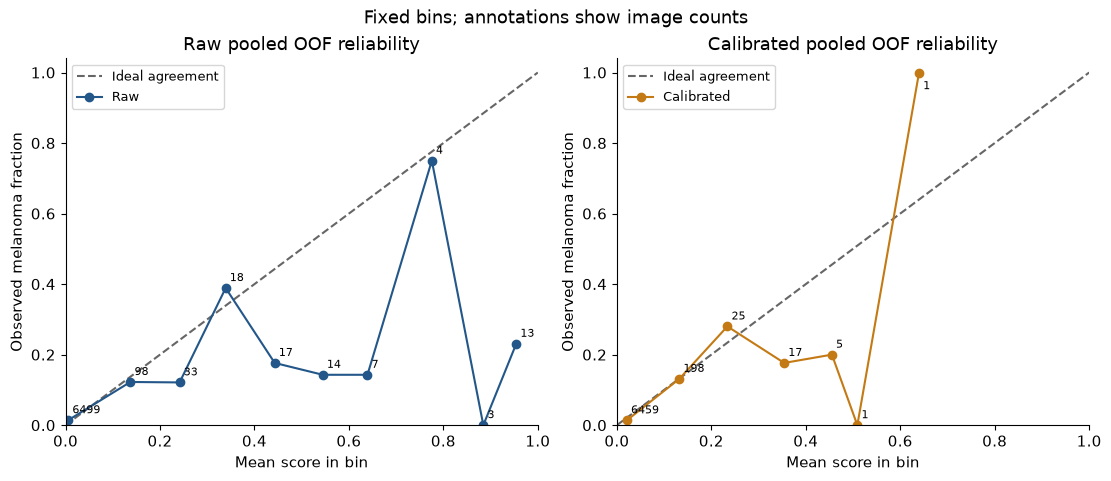

,bin,lower,upper,n_images,n_positive,mean_probability,observed_prevalence,model
0,0,0.0,0.1,6499,92,0.005610,0.014156,Raw
1,1,0.1,0.2,98,12,0.137267,0.122449,Raw
2,2,0.2,0.3,33,4,0.241452,0.121212,Raw
3,3,0.3,0.4,18,7,0.339054,0.388889,Raw
4,4,0.4,0.5,17,3,0.442833,0.176471,Raw
5,5,0.5,0.6,14,2,0.544697,0.142857,Raw
6,6,0.6,0.7,7,1,0.639248,0.142857,Raw
7,7,0.7,0.8,4,3,0.775557,0.750000,Raw
8,8,0.8,0.9,3,0,0.884586,0.000000,Raw
9,9,0.9,1.0,13,3,0.954277,0.230769,Raw


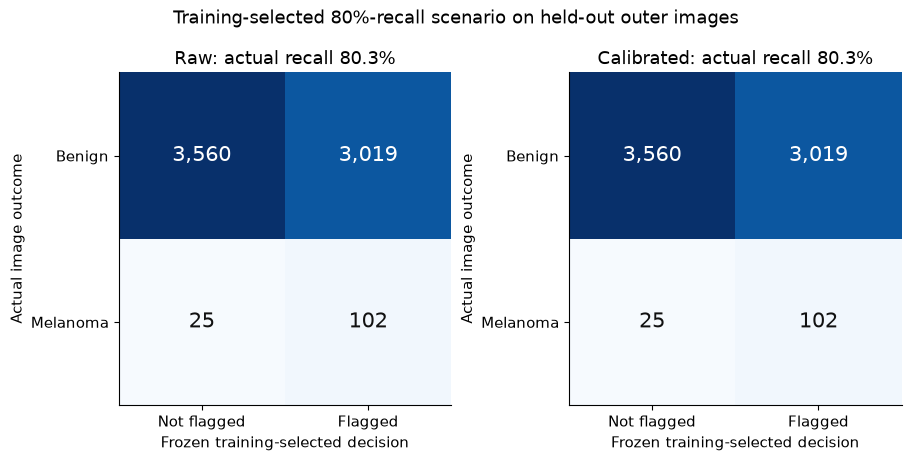

A monotonic map preserves within-fold ranking. Different fold-specific maps can change pooled ordering. Calibration is assessed with log loss, Brier and reliability; the academic training-only 80%-recall rule does not guarantee 80% recall on held-out patients.

In [17]:
image_docs.calibration_figures(calibration, finish_figure)

In [18]:
if calibration['complete']:
    display(calibration['ranking_invariance'])
    display(calibration['scenario_by_fold'])

,fold,raw_average_precision,calibrated_average_precision,ap_difference,raw_roc_auc,calibrated_roc_auc,ap_invariant,roc_auc_invariant,changed_training_selected_decisions
0,0,0.152537,0.152537,0.000000e+00,0.854419,0.854419,True,True,0
1,1,0.148876,0.148876,0.000000e+00,0.839179,0.839179,True,True,0
2,2,0.148730,0.148730,0.000000e+00,0.864823,0.864823,True,True,0
3,3,0.057262,0.057262,-6.938894e-18,0.757266,0.757266,True,True,0
4,4,0.150444,0.150444,0.000000e+00,0.838316,0.838316,True,True,0


,fold,model,n_images,n_patients,n_positive,training_target_recall,threshold,threshold_scope,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction,recall,f1
0,0,raw,1344,84,24,0.8,0.000056,fixed per outer fold from training-only OOF sc...,24,1207,113,0,1.000000,0.085606,0.019496,0.915923,1.000000,0.038247
1,0,calibrated,1344,84,24,0.8,0.016348,fixed per outer fold from training-only OOF sc...,24,1207,113,0,1.000000,0.085606,0.019496,0.915923,1.000000,0.038247
2,1,raw,1366,84,26,0.8,0.002104,fixed per outer fold from training-only OOF sc...,24,490,850,2,0.923077,0.634328,0.046693,0.376281,0.923077,0.088889
3,1,calibrated,1366,84,26,0.8,0.017208,fixed per outer fold from training-only OOF sc...,24,490,850,2,0.923077,0.634328,0.046693,0.376281,0.923077,0.088889
4,2,raw,1328,87,26,0.8,0.006221,fixed per outer fold from training-only OOF sc...,22,336,966,4,0.846154,0.741935,0.061453,0.269578,0.846154,0.114583
5,2,calibrated,1328,87,26,0.8,0.015723,fixed per outer fold from training-only OOF sc...,22,336,966,4,0.846154,0.741935,0.061453,0.269578,0.846154,0.114583
6,3,raw,1371,82,25,0.8,0.001956,fixed per outer fold from training-only OOF sc...,7,148,1198,18,0.280000,0.890045,0.045161,0.113056,0.280000,0.077778
7,3,calibrated,1371,82,25,0.8,0.018041,fixed per outer fold from training-only OOF sc...,7,148,1198,18,0.280000,0.890045,0.045161,0.113056,0.280000,0.077778
8,4,raw,1297,85,26,0.8,0.000228,fixed per outer fold from training-only OOF sc...,25,838,433,1,0.961538,0.340677,0.028969,0.665382,0.961538,0.056243
9,4,calibrated,1297,85,26,0.8,0.015263,fixed per outer fold from training-only OOF sc...,25,838,433,1,0.961538,0.340677,0.028969,0.665382,0.961538,0.056243


### Matched metadata comparison

When present, metadata scores come from the clean hash-recorded OOF
prediction bundle with verified retained identities. The image-minus-metadata
interval uses the **same patient draw** for both models. Positive AP or ROC-AUC
differences favour the image model; negative log-loss or Brier differences
favour it. These are paired development comparisons after prior diagnostics.


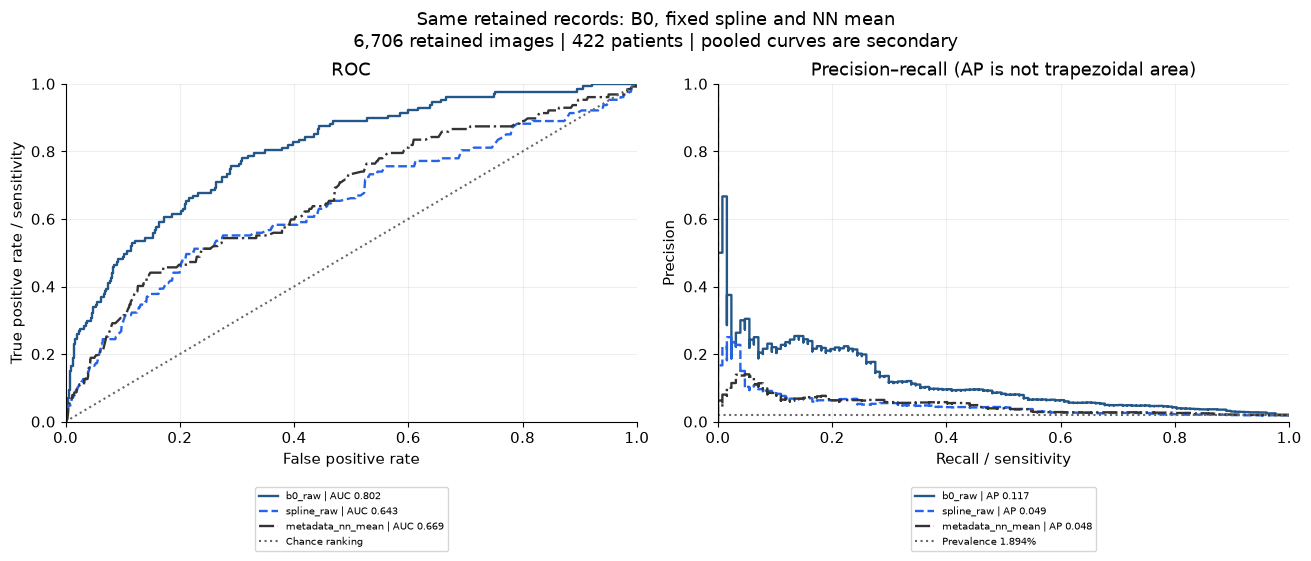

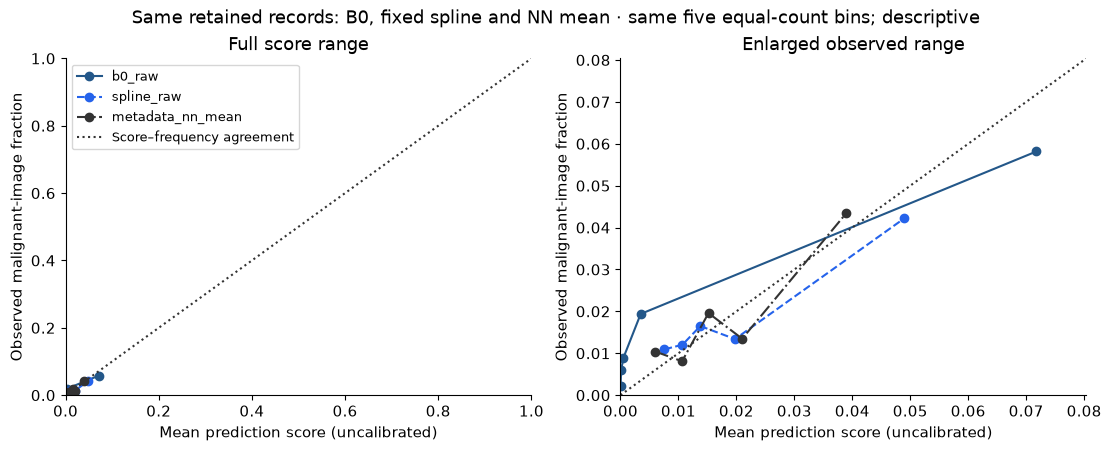

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,model
0,1,1342,3,0.000017,0.002235,2.590740e-09,0.000050,164,b0_raw
1,2,1341,8,0.000110,0.005966,4.980170e-05,0.000201,217,b0_raw
2,3,1341,12,0.000517,0.008949,2.014816e-04,0.001118,286,b0_raw
3,4,1341,26,0.003487,0.019389,1.118944e-03,0.007783,329,b0_raw
4,5,1341,78,0.071764,0.058166,7.784358e-03,0.991087,309,b0_raw
5,1,1371,15,0.007594,0.010941,2.805209e-03,0.009150,121,spline_raw
6,2,1329,16,0.010693,0.012039,9.175152e-03,0.011864,162,spline_raw
7,3,1334,22,0.013772,0.016492,1.193646e-02,0.016044,187,spline_raw
8,4,1344,18,0.019765,0.013393,1.617859e-02,0.025073,203,spline_raw
9,5,1328,56,0.048934,0.042169,2.537785e-02,0.421284,198,spline_raw


In [19]:
image_docs.matched_comparator_figures(score_bundle(), finish_figure)

## Takeaways

Use mean-fold AP and its conditional patient interval together with fold
variation when assessing this image model. Pooled AP, raw-score reliability and
the declared-cutoff confusion counts answer complementary questions. Preserve
the development caveat when presenting these results; the reserved test is the
remaining independent assessment after all decisions are frozen.


In [20]:
image_docs.image_takeaways(raw, comparison_table())

**Executed clean B0 result:** mean outer-fold AP **0.1316** and mean ROC-AUC **0.8308**. AP ranges from **0.057 to 0.153** across the five retained patient groups. The observed fold spread is descriptive variability, not a confidence interval. These values replace the historical pilot findings; they remain development evidence after earlier exploration.

,population,model,aggregation,fold,weighting,n_images,n_patients,n_malignant_images,n_malignant_patients,average_precision,roc_auc,log_loss,brier,role
7,clean,b0_raw,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.131570,0.830801,0.099116,0.019637,predeclared
10,clean,metadata_nn_mean,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.059570,0.676694,0.090169,0.018382,predeclared
17,clean,spline_raw,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.064842,0.655631,0.091006,0.018422,predeclared
